# **VISUALIZATION OTUPUT 2D**

## FUNCTION

**Start slice** → first slice where pancreas area ≥ 20% of the maximum \
**Central slice** → slice at the midpoint among all slices containing pancreas (NOT the one with maximum area) \
**End slice** → last slice where pancreas area ≥ 20% of the maximum

In [1]:
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
import torch
from pathlib import Path


@torch.no_grad()
def show_prediction_patient_3slices(
    model,
    ct_dir,
    mask_dir,
    patient_id: str,
    threshold: float = 0.5,
    alpha: float = 0.35,
    window: tuple | None = None,   # e.g. (-100, 200) for HU
    device: torch.device | str = "cuda",
    area_ratio: float = 0.20,      # 20% of max area for first/last slice
):
    device = torch.device(device) if isinstance(device, str) else device

    ct_path = Path(ct_dir) / f"pancreas_{patient_id}.nii.gz"
    m_path  = Path(mask_dir) / f"label{patient_id}.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(str(ct_path))).astype(np.float32)   # (Z,Y,X)
    gt = sitk.GetArrayFromImage(sitk.ReadImage(str(m_path))).astype(np.uint8)      # (Z,Y,X)

    # Compute pancreas area per slice
    areas = gt.reshape(gt.shape[0], -1).sum(axis=1)
    pos = np.where(areas > 0)[0]

    if len(pos) == 0:
        print(f"No pancreas found in GT for patient {patient_id}.")
        return

    # Central slice
    central_idx = int(pos[len(pos) // 2])

    # Threshold for "significant" slices
    max_area = areas[pos].max()
    area_thr = area_ratio * max_area

    significant_pos = pos[areas[pos] >= area_thr]

    if len(significant_pos) >= 2:
        first_idx = int(significant_pos[0])
        last_idx = int(significant_pos[-1])
    else:
        # fallback
        first_idx = int(pos[0])
        last_idx = int(pos[-1])

    selected_slices = [first_idx, central_idx, last_idx]
    row_titles = ["Pancreas start", "Central slice", "Pancreas end"]

    model.eval()

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))

    summary = []

    for r, z in enumerate(selected_slices):
        img = ct[z]
        gt2d = (gt[z] > 0).astype(np.uint8)

        # Model prediction
        x = torch.from_numpy(img[None, None, ...]).to(device)
        logits = model(x)
        prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
        pred2d = (prob >= threshold).astype(np.uint8)

        # Windowing for visualization
        disp = img.copy()
        if window is not None:
            lo, hi = window
            disp = np.clip(disp, lo, hi)

        # Column 1: original image
        axes[r, 0].imshow(disp, cmap="gray")
        axes[r, 0].set_title(f"{row_titles[r]} | z={z}")
        axes[r, 0].axis("off")

        # Column 2: GT overlay
        axes[r, 1].imshow(disp, cmap="gray")
        axes[r, 1].imshow(gt2d, cmap="Reds", alpha=alpha, interpolation="nearest")
        axes[r, 1].set_title("Ground Truth")
        axes[r, 1].axis("off")

        # Column 3: Prediction overlay
        axes[r, 2].imshow(disp, cmap="gray")
        axes[r, 2].imshow(pred2d, cmap="Blues", alpha=alpha, interpolation="nearest")
        axes[r, 2].set_title(f"Prediction (thr={threshold})")
        axes[r, 2].axis("off")

        summary.append({
            "slice": z,
            "gt_pixels": int(gt2d.sum()),
            "pred_pixels": int(pred2d.sum()),
            "prob_min": float(prob.min()),
            "prob_max": float(prob.max()),
        })

    plt.suptitle(f"Patient {patient_id} - Original / GT / Prediction", fontsize=16)
    plt.tight_layout()
    plt.show()

    print(f"\nPatient {patient_id}")
    print(f"Selected slices: start={first_idx}, center={central_idx}, end={last_idx}")
    print(f"Significant area threshold: {area_thr:.2f} pixels ({area_ratio*100:.0f}% of max area)\n")

    for i, s in enumerate(summary):
        print(
            f"{row_titles[i]} | z={s['slice']} | "
            f"GT pixels={s['gt_pixels']} | Pred pixels={s['pred_pixels']} | "
            f"prob min/max=({s['prob_min']:.4f}, {s['prob_max']:.4f})"
        )

## **Baseline ResNet**

In [2]:
import torch
import torch.nn as nn
import torchvision.models as models


# =========================
# Decoder block
# =========================
class DecoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


# =========================
# Model
# =========================
class ResNet34Baseline(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()

        self.channel_adapt = nn.Conv2d(1, 3, kernel_size=1, bias=False)

        backbone = models.resnet34(
            weights=models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
        )

        self.encoder = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1,
            backbone.layer2,
            backbone.layer3,
            backbone.layer4,
        )

        self.dec1 = DecoderBlock(512, 256)
        self.dec2 = DecoderBlock(256, 128)
        self.dec3 = DecoderBlock(128, 64)
        self.dec4 = DecoderBlock(64, 32)
        self.dec5 = DecoderBlock(32, 16)

        self.head = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        x = self.channel_adapt(x)
        x = self.encoder(x)
        x = self.dec1(x)
        x = self.dec2(x)
        x = self.dec3(x)
        x = self.dec4(x)
        x = self.dec5(x)
        x = self.head(x)
        return x


# =========================
# Load model + checkpoint
# =========================

DEVICE = torch.device("cpu")

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\baseline_resnet\best_resnet34_heavy_decoder.pt"

model_resnet = ResNet34Baseline(pretrained=False).to(DEVICE)

state_dict = torch.load(ckpt_path, map_location=DEVICE)
model_resnet.load_state_dict(state_dict)

model_resnet.eval()

ResNet34Baseline(
  (channel_adapt): Conv2d(1, 3, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      

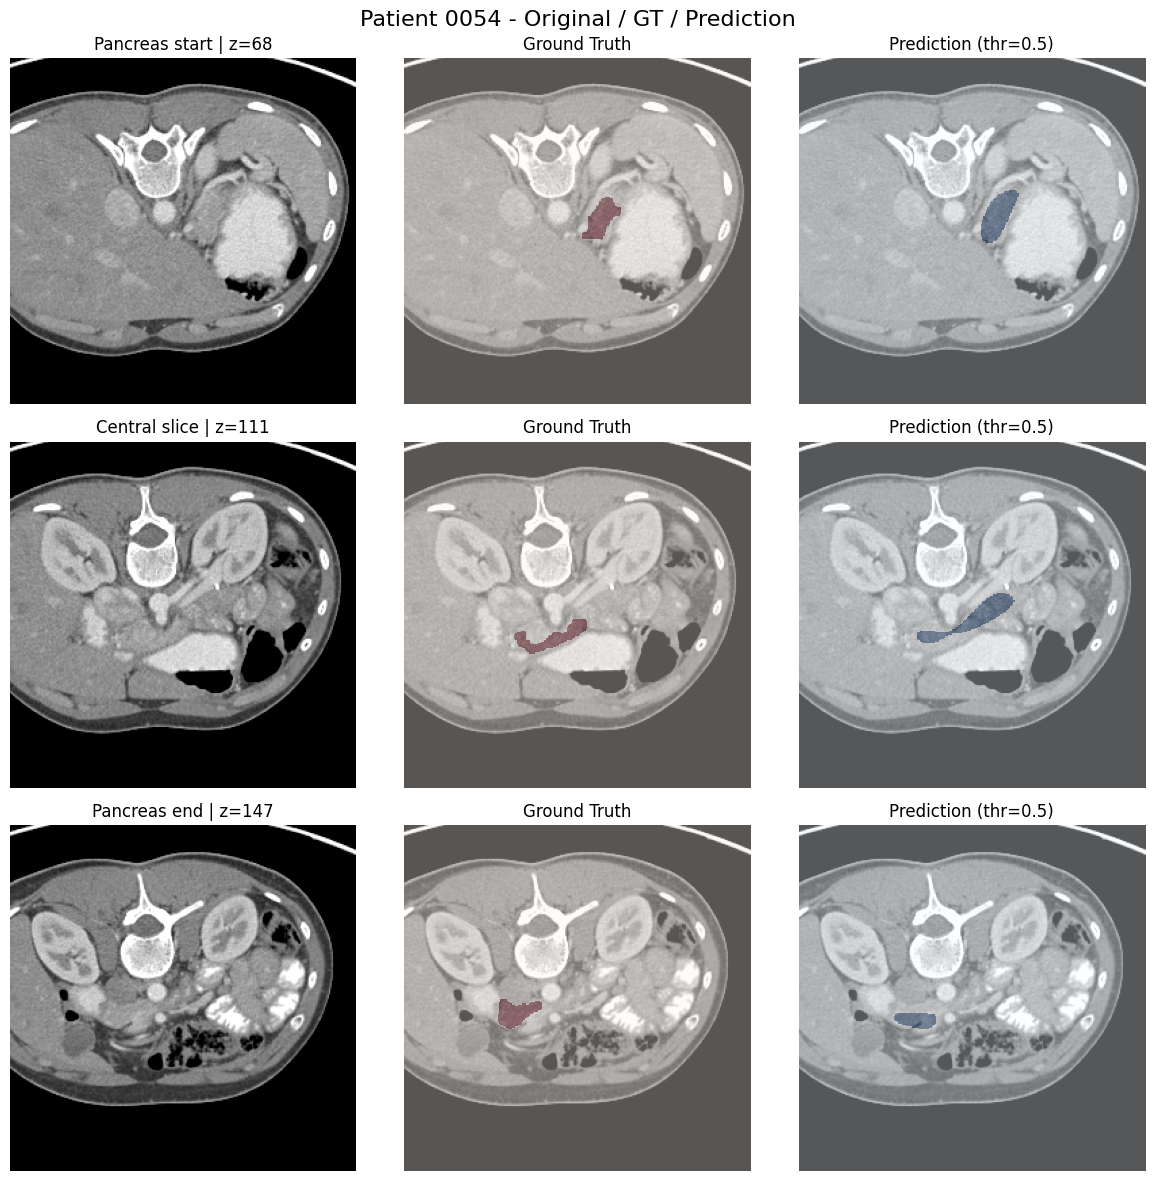


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=629 | prob min/max=(0.0000, 0.9999)
Central slice | z=111 | GT pixels=505 | Pred pixels=740 | prob min/max=(0.0000, 0.9982)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=299 | prob min/max=(0.0000, 1.0000)


In [4]:
show_prediction_patient_3slices(
    model=model_resnet,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\mask",
    patient_id="0054",   
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),        
    device=DEVICE,
    area_ratio=0.20,
)

## **First UNET2D (Baseline)**

In [21]:
import torch
import segmentation_models_pytorch as smp

device = "cpu"

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\first_unet\best_unet2d_baseline.pt"  
state_dict = torch.load(ckpt_path, map_location=device)

model1 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None, 
    in_channels=1,
    classes=1
).to(device)

model1.load_state_dict(state_dict)
model1.eval()

print("Loaded SMP Unet (resnet34) from:", ckpt_path)

Loaded SMP Unet (resnet34) from: C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\first_unet\best_unet2d_baseline.pt


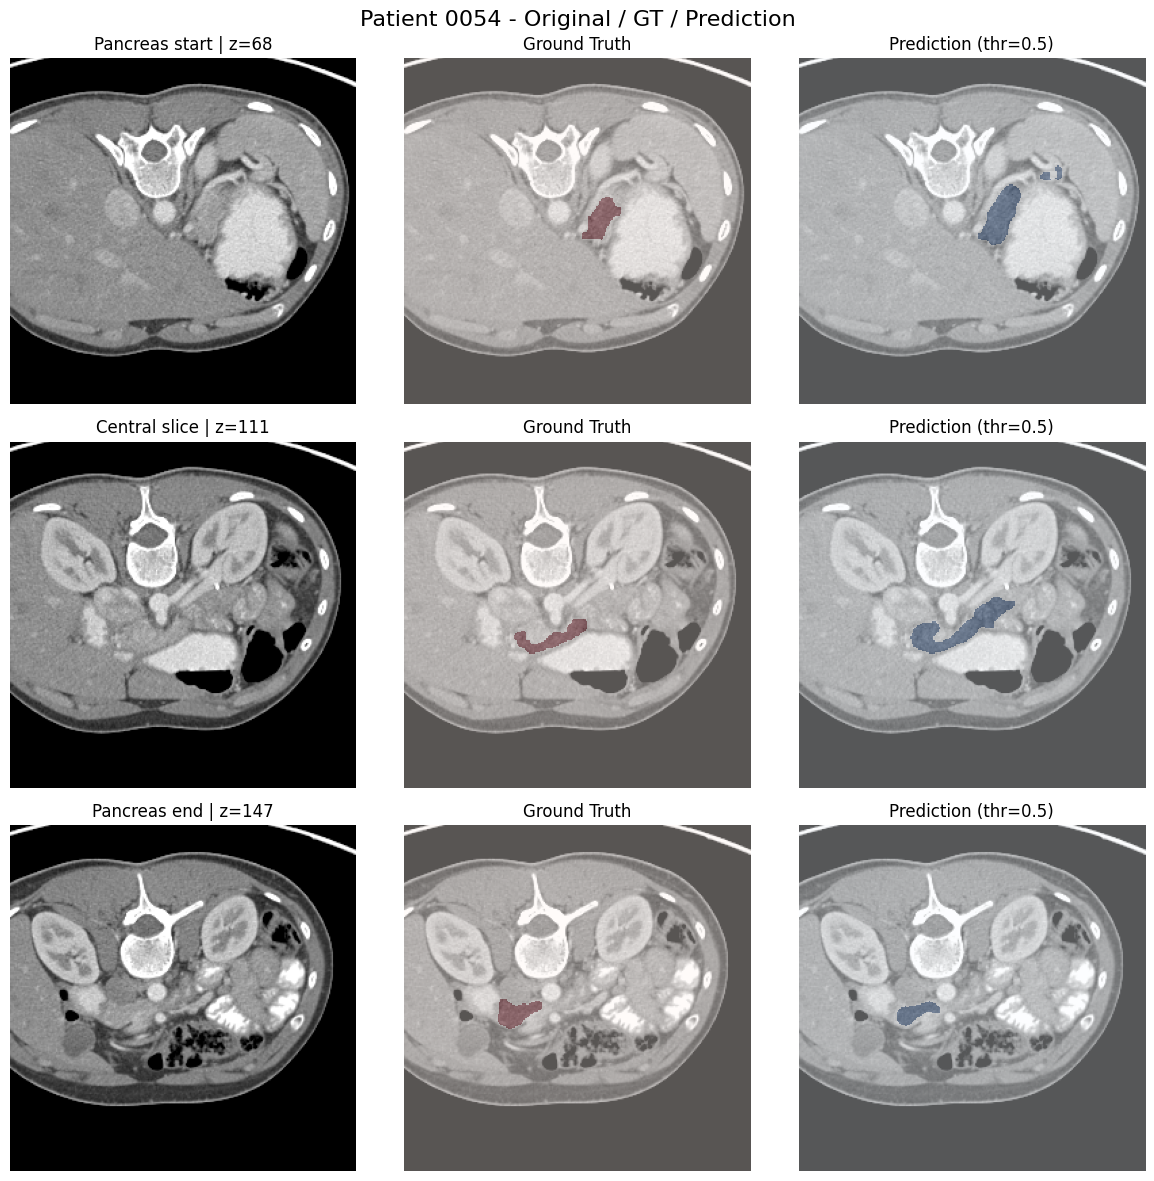


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=826 | prob min/max=(0.0000, 1.0000)
Central slice | z=111 | GT pixels=505 | Pred pixels=1084 | prob min/max=(0.0000, 0.9999)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=302 | prob min/max=(0.0000, 0.9970)


In [22]:
show_prediction_patient_3slices(
    model=model1,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),   
    device=device,
    area_ratio=0.20
)

## **Second UNET2D**

In [27]:
import torch
import segmentation_models_pytorch as smp

device = "cpu"

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303\best_unet2d.pt"  
state_dict = torch.load(ckpt_path, map_location=device)

model2 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None, 
    in_channels=1,
    classes=1
).to(device)

model2.load_state_dict(state_dict)
model2.eval()

print("Loaded SMP Unet (resnet34) from:", ckpt_path)

Loaded SMP Unet (resnet34) from: C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303\best_unet2d.pt


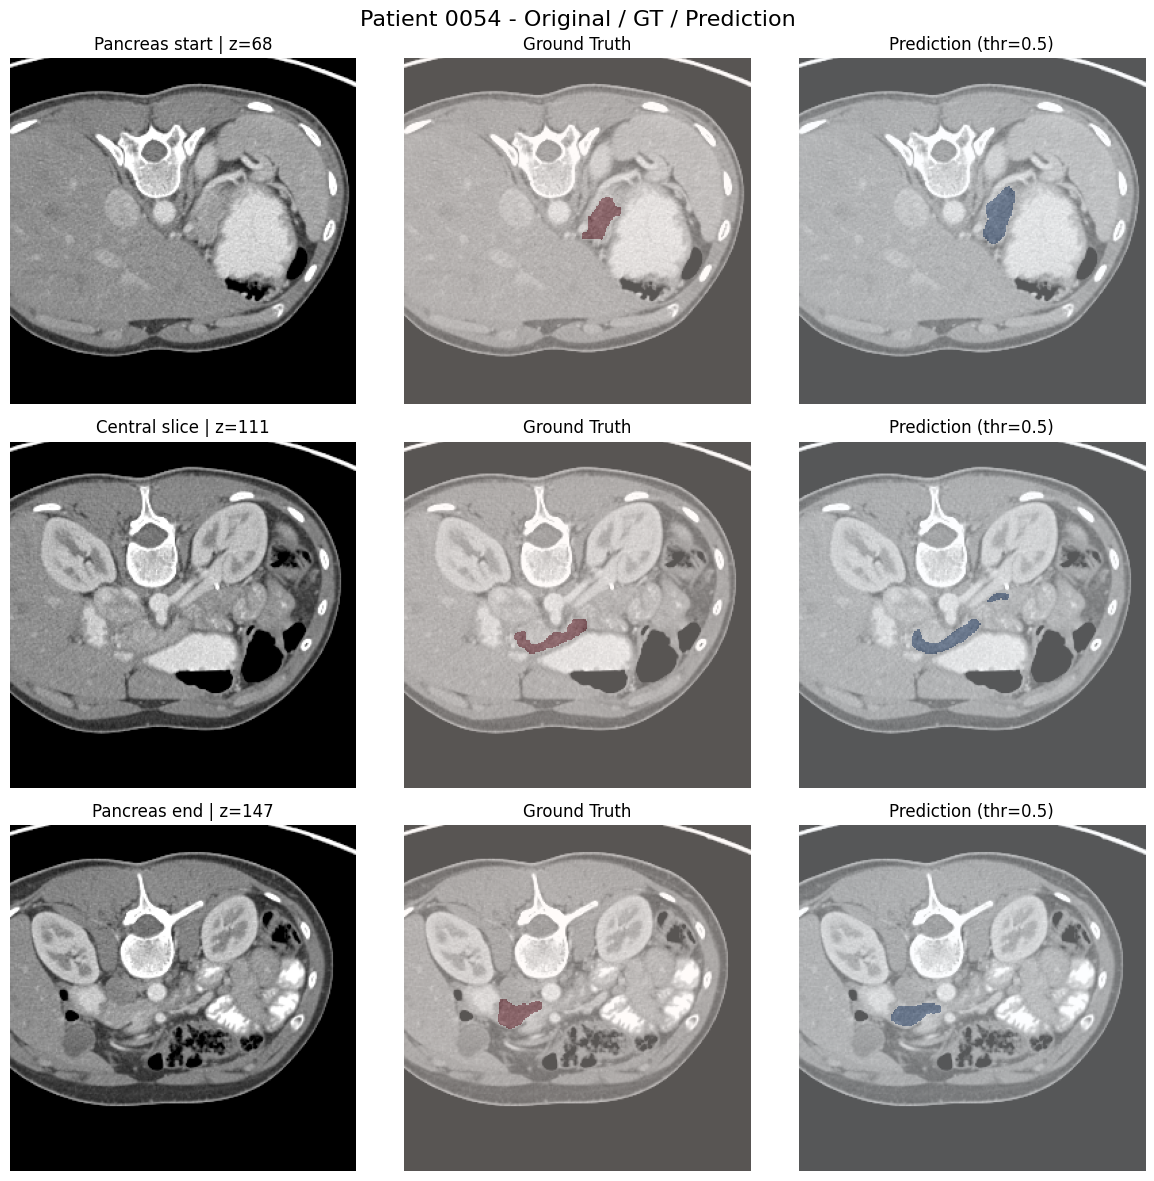


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=621 | prob min/max=(0.0000, 1.0000)
Central slice | z=111 | GT pixels=505 | Pred pixels=576 | prob min/max=(0.0000, 0.9999)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=398 | prob min/max=(0.0000, 1.0000)


In [28]:
show_prediction_patient_3slices(
    model=model2,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),   
    device=device,
    area_ratio=0.20
)

## **Third UNET2D: Sanity Check**

In [31]:
import torch
import segmentation_models_pytorch as smp

device = "cpu"

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303_2 (adj il 15 marzo)\best_unet2d_sanity.pt"  
state_dict = torch.load(ckpt_path, map_location=device)

model3 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None, 
    in_channels=1,
    classes=1
).to(device)

model3.load_state_dict(state_dict)
model3.eval()
    
print("Loaded SMP Unet (resnet34) from:", ckpt_path)

Loaded SMP Unet (resnet34) from: C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303_2 (adj il 15 marzo)\best_unet2d_sanity.pt


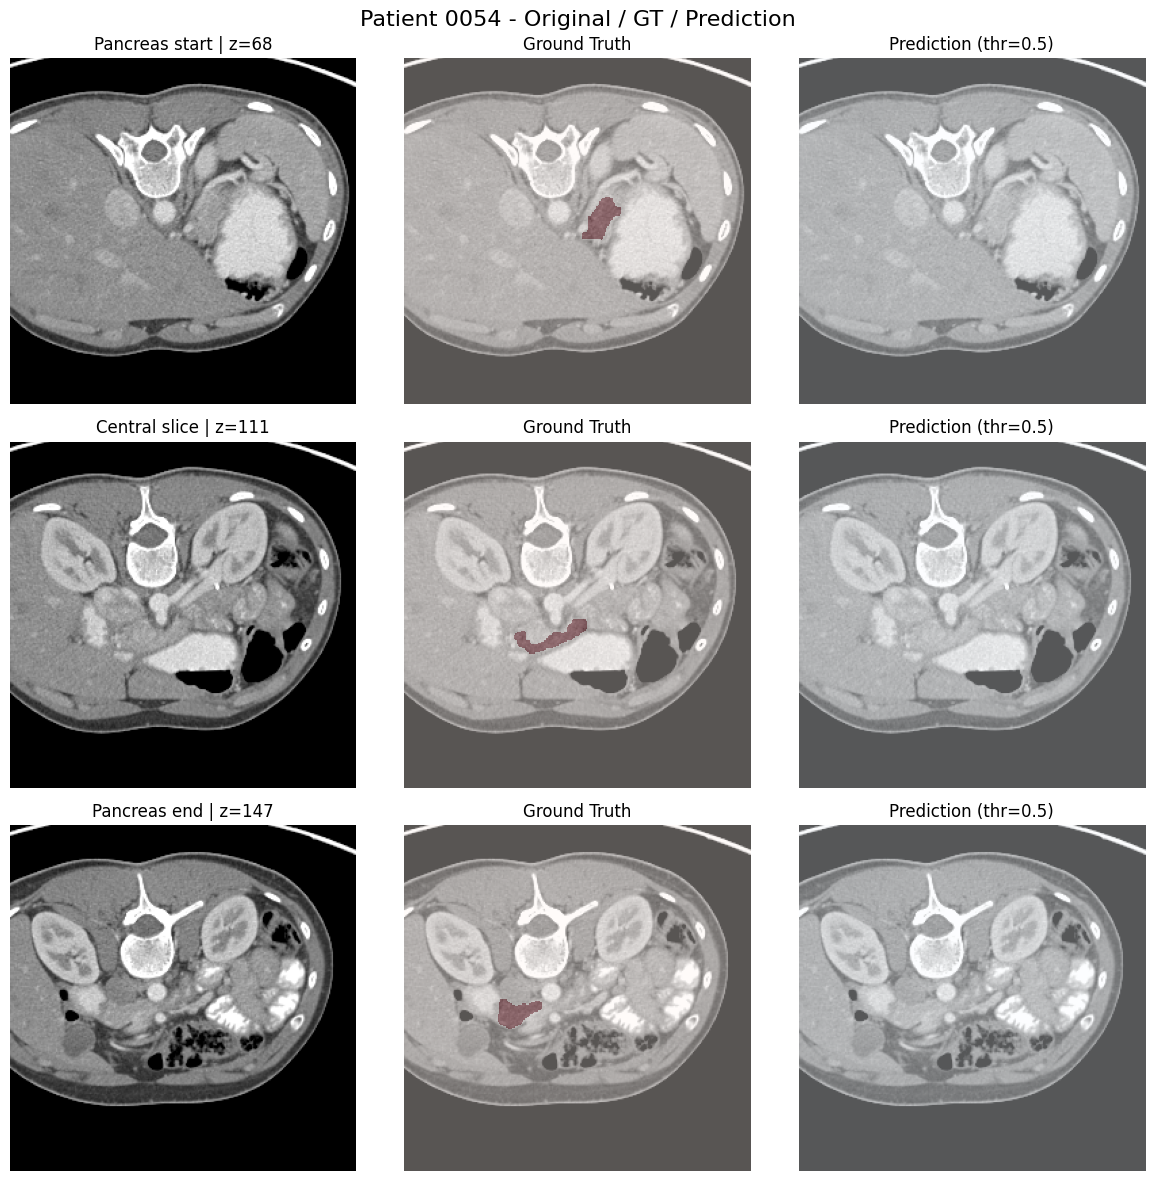


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=0 | prob min/max=(0.0071, 0.2623)
Central slice | z=111 | GT pixels=505 | Pred pixels=0 | prob min/max=(0.0080, 0.2678)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=0 | prob min/max=(0.0074, 0.2668)


In [32]:
show_prediction_patient_3slices(
    model=model3,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),   
    device=device,
    area_ratio=0.20
)

## **Fourth UNET2D**

In [33]:
import torch
import segmentation_models_pytorch as smp

device = "cpu"

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303_3\best_unet2d_tversky.pt"  
state_dict = torch.load(ckpt_path, map_location=device)

model4 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None, 
    in_channels=1,
    classes=1
).to(device)

model4.load_state_dict(state_dict)
model4.eval()
    
print("Loaded SMP Unet (resnet34) from:", ckpt_path)

Loaded SMP Unet (resnet34) from: C:\Users\pietr\Desktop\Visualizzazione otuput 2d\models 2d\prova1303_3\best_unet2d_tversky.pt


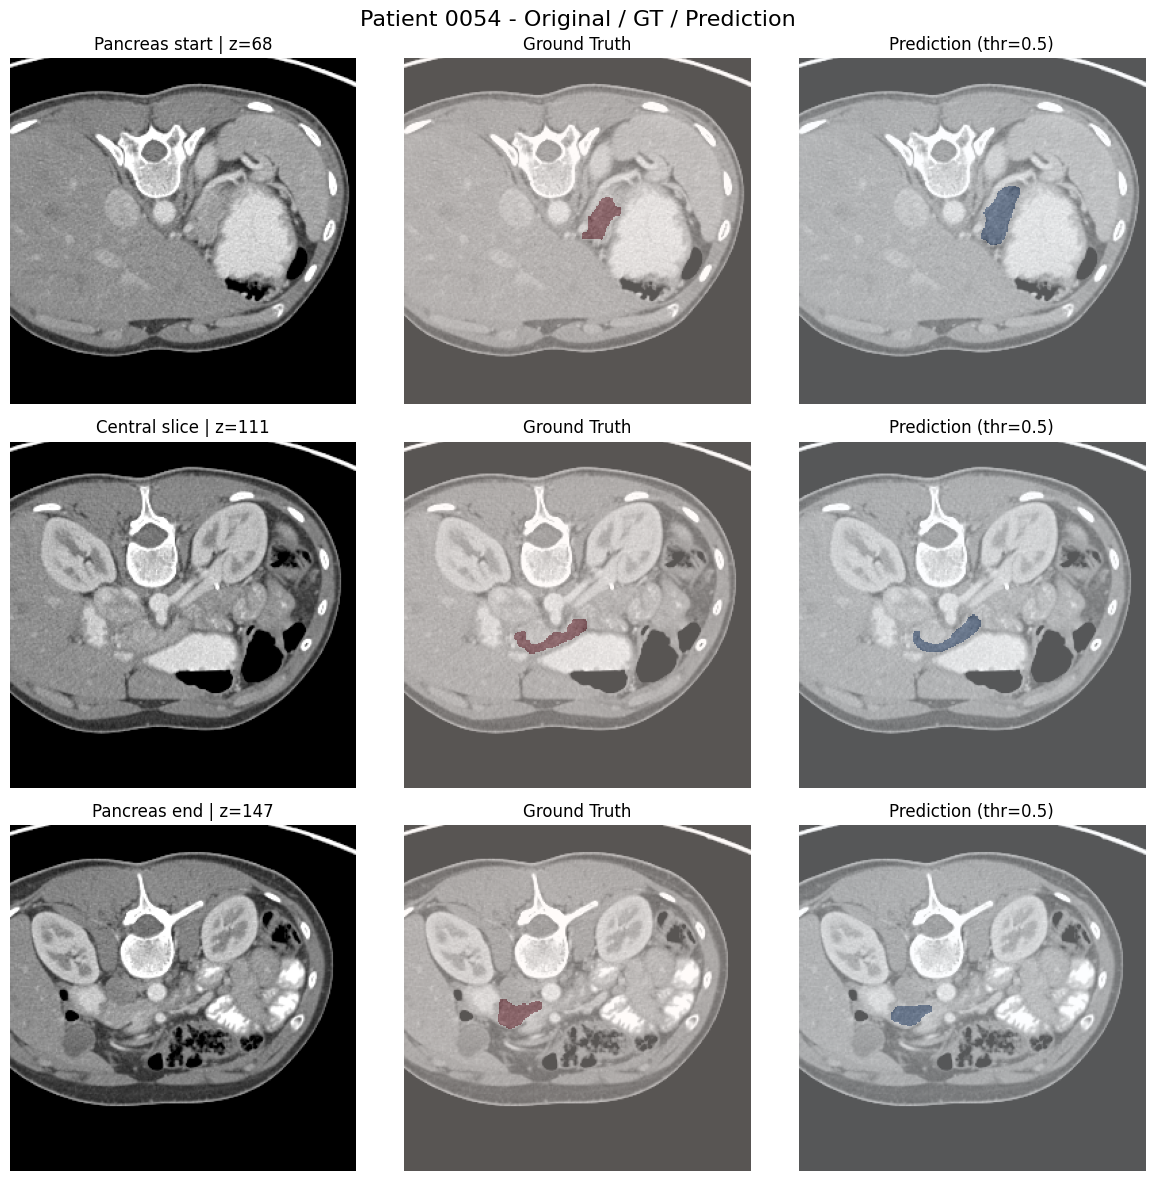


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=734 | prob min/max=(0.0000, 1.0000)
Central slice | z=111 | GT pixels=505 | Pred pixels=478 | prob min/max=(0.0000, 0.9996)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=336 | prob min/max=(0.0000, 1.0000)


In [39]:
show_prediction_patient_3slices(
    model=model4,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 2d\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),   
    device=device,
    area_ratio=0.20
)